In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data))
    return fig

**Gene code to gene name**

In [8]:
f = open('/home/ctrader/region_similarity/data/mart_export_protein_coding_genes_unique_with_proteinID_CT20220712.cleaned.bed', 'r')
id2gene = {}
for line in f.readlines():
    line = line.strip().split('\t')
    id2gene[line[5]] = line[3]
pickle_out = open('/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle', 'wb')
pickle.dump(id2gene, pickle_out)
pickle_out.close()

**STRING dataset**

In [3]:
string_overall_path = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
f = open(string_overall_path, 'r')
string_cols = f.readline().strip().split()

string_scores = []
for line in f.readlines():
    string_scores.append(line.strip().replace('9606.', '').split())
f.close()

string_scores = np.array(string_scores)

In [39]:
# #20220711 saving all associations instead of top 1000, and taking max of transferred and non-transferred scores
# for ind in [2, 4, 5, 6, 7, 9, 11, 13, 15]:
#     if ind in [2, 7, 9, 11, 13]: #if there is a transferred component or not
#         metric = string_cols[ind] + '_human_transferred_max'
#         print(string_cols[ind] + ' and ' + string_cols[ind+1])
#         data_out = string_scores[:, [0, 1]]
#         #take max of human and transferred associations
#         max_data = np.max(string_scores[:, [ind, ind+1]].astype(int), axis=1).reshape(-1, 1)
#         data_out = np.hstack((data_out, max_data))
#     else:
#         metric = string_cols[ind]
#         print(metric)
#         data_out = string_scores[:, [0, 1, ind]]

#     string_out_path = '/home/ctrader/region_similarity/data/STRING/9606.protein.links.v11.5.' + metric + '.all_associations.CT20220711.txt'
#     np.savetxt(string_out_path, data_out, delimiter="\t", fmt="%s")

neighborhood and neighborhood_transferred
fusion
cooccurence
homology
coexpression and coexpression_transferred
experiments and experiments_transferred
database and database_transferred
textmining and textmining_transferred
combined_score


In [9]:
# #20220707 saving all associations instead of top 1000 to see if this has any affect on final scores
# for metric, ind in zip(string_cols[2:], range(2, len(string_scores[0]))):
#     print(metric)
#     data = string_scores[:, [0, 1, ind]]
    
#     string_out_path = '/home/ctrader/region_similarity/data/STRING/9606.protein.links.v11.5.' + metric + '.all_associations.CT20220707.txt'
#     np.savetxt(string_out_path, data, delimiter="\t", fmt="%s")

neighborhood
neighborhood_transferred
fusion
cooccurence
homology
coexpression
coexpression_transferred
experiments
experiments_transferred
database
database_transferred
textmining
textmining_transferred
combined_score


In [65]:
# for metric, ind in zip(string_cols[2:], range(2, len(string_scores[0]))):
#     print(metric)
#     data = string_scores[:, [0, 1, ind]]
    
#     #creating 2 dictionaries, one for protein associations and one for scores. We want the top 1000 string scores
#     #for each protein
#     protein2protein = {}
#     protein2score = {}
#     for assoc in data:
#         if assoc[0] not in protein2protein:
#             protein2protein[assoc[0]] = np.array([assoc[1]])
#             protein2score[assoc[0]] = np.array([int(assoc[2])])
#         else:
#             protein2protein[assoc[0]] = np.append(protein2protein[assoc[0]], [assoc[1]])
#             protein2score[assoc[0]] = np.append(protein2score[assoc[0]], [int(assoc[2])])

#     #take top 1000 protein associations
#     protein2protein_top1000 = {}
#     protein2score_top1000 = {}
#     protein_names = np.array(list(protein2protein.keys()))
#     for protein in protein_names:
#         #get proteins and scores
#         protein_arr = protein2protein[protein]
#         score_arr = protein2score[protein]
#         #find top 1000
#         top_1000_inds = np.argsort(-score_arr)[:1000]
#         top_1000_proteins = protein_arr[top_1000_inds]
#         top_1000_scores = score_arr[top_1000_inds]
#         #create new dictionary entries
#         protein2protein_top1000[protein] = top_1000_proteins
#         protein2score_top1000[protein] = top_1000_scores

#     string_top_1000_path = '/home/ctrader/region_similarity/data/STRING/9606.protein.links.v11.5.' + metric + '.top_1000_associations.CT20220705.txt'
#     f = open(string_top_1000_path, "w")
#     for protein in protein_names:
#         protein_arr = protein2protein_top1000[protein]
#         score_arr = protein2score_top1000[protein]
#         for protein_2, score in zip(protein_arr, score_arr):
#             f.write(protein + '\t' + protein_2 + '\t' + str(score) + '\n')

neighborhood
neighborhood_transferred
fusion
cooccurence
homology
coexpression
coexpression_transferred
experiments
experiments_transferred
database
database_transferred
textmining
textmining_transferred
combined_score


**Cleaning up Gene Dataset**

In [3]:
# #cleaning up genes dataset
# f = open('/home/ctrader/region_similarity/data/mart_export_protein_coding_genes_unique_CT20220628.bed', 'r')
# out_data = []
# for line in f.readlines():
#     line = line.strip().split('\t')
#     if (len(line) == 5):
#         if (line[3] == ''):
#             line[3] = 'nan'
#         if '[' in line[4]:
#             line[4] = line[4][:line[4].index('[')]
#         line = '\t'.join(line)
#         line += '\n'
#         out_data.append(line)
# f.close()

# out_file = open('/home/ctrader/region_similarity/data/mart_export_protein_coding_genes_unique_cleaned_CT20220628.bed', 'w')
# out_file.writelines(out_data)
# out_file.close()

In [3]:
# #curate a list of descriptor terms
# f = open('/home/ctrader/region_similarity/data/mart_export_protein_coding_genes_unique_cleaned_CT20220628.bed', 'r')
# descriptor_terms = np.array([])
# for line in f.readlines():
#     line = line.strip().split('\t')
#     descriptor = line[4].lower()
#     descriptor = descriptor.replace('(', '').replace(')', '')
#     descriptor_terms = np.append(descriptor_terms, descriptor.split())
# descriptor_terms = np.unique(descriptor_terms)
# f.close()

# stop_words = ['of', 'the', 'a', 'protein', 'and', 'like', 'with', 'domain', 'containing', 'member', 
#               'associated', 'family', 'non', 'paired', 'one', 'two', 'three', 'four', 'five', 'six', 
#               'seven', 'eight', 'nine', 'ten', 'class', 'related', 'bound', 'type', 'pro', '-']
# unwanted_chars = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '0', '-', ',', '/', '.']
# for descriptor in descriptor_terms:
#     char_count_dict = Counter(descriptor)
#     unwanted_sum = 0
#     for char in unwanted_chars:
#         unwanted_sum += char_count_dict[char]
#     if ((descriptor.isnumeric()) | 
#         (descriptor in stop_words) | 
#         (unwanted_sum >= len(descriptor) / 2) | 
#         (len(descriptor) < 2)):
#         descriptor_terms = descriptor_terms[descriptor_terms!=descriptor]

In [4]:
# DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHScosine.hdf5'
# TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFcosine.hdf5'
# epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogoscosine.hdf5'

# DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
# DHS_scaled_vals_full = DHS_hdf5['top_1000_scaled_vals'][:]
# DHS_similar_regions_full = DHS_hdf5['top_1000_similar_regions'][:]
# DHS_hdf5.close()

# TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
# TF_scaled_vals_full = TF_hdf5['top_1000_scaled_vals'][:]
# TF_similar_regions_full = TF_hdf5['top_1000_similar_regions'][:]
# TF_hdf5.close()

# epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
# epilogos_scaled_vals_full = epilogos_hdf5['top_1000_scaled_vals'][:]
# epilogos_similar_regions_full = epilogos_hdf5['top_1000_similar_regions'][:]
# epilogos_hdf5.close()

In [5]:
# f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220628.cleanedgenesmapped.bed', 'r')
# mapped_genes = f.readlines()
# f.close()

In [ ]:
# def curate_descriptor_terms(genes_bed_path):
#     #curate a list of descriptor terms
#     f = open(genes_bed_path, 'r')
#     descriptor_terms = np.array([])
#     for line in f.readlines():
#         line = line.strip().split('\t')
#         descriptor = line[4].lower()
#         descriptor = descriptor.replace('(', '').replace(')', '')
#         descriptor_terms = np.append(descriptor_terms, descriptor.split())
#     descriptor_terms = np.unique(descriptor_terms)
#     f.close()

#     stop_words = ['of', 'the', 'a', 'protein', 'and', 'like', 'with', 'domain', 'containing', 'member',
#                   'associated', 'family', 'non', 'paired', 'one', 'two', 'three', 'four', 'five', 'six',
#                   'seven', 'eight', 'nine', 'ten', 'class', 'related', 'bound', 'type', 'pro', '-']
#     unwanted_chars = ['1', '2', '3', '4', '5', '6', '7', '8', '9', '0', '-', ',', '/', '.']
#     for descriptor in descriptor_terms:
#         char_count_dict = Counter(descriptor)
#         unwanted_sum = 0
#         for char in unwanted_chars:
#             unwanted_sum += char_count_dict[char]
#         if ((descriptor.isnumeric()) |
#             (descriptor in stop_words) |
#             (unwanted_sum >= len(descriptor) / 2) |
#             (len(descriptor) < 2)):
#             descriptor_terms = descriptor_terms[descriptor_terms!=descriptor]
#     return descriptor_terms

In [ ]:
# def count_terms(descriptor_terms, DHS_scaled_vals, DHS_similar_regions, TF_scaled_vals, TF_similar_regions, epilogos_scaled_vals, epilogos_similar_regions, mapped_genes, roi):
#     term_roi_counts = np.zeros(len(descriptor_terms), dtype=int)
#     #DHS scores
#     DHS_arr = np.zeros(len(DHS_scaled_vals))
#     DHS_arr[DHS_similar_regions[roi]] = DHS_scaled_vals[roi]
#     #epilogos scores
#     epilogos_arr = np.zeros(len(DHS_scaled_vals))
#     epilogos_arr[epilogos_similar_regions[roi]] = epilogos_scaled_vals[roi]
#     #TF motif scores
#     TF_arr = np.zeros(len(DHS_scaled_vals))
#     TF_arr[TF_similar_regions[roi]] = TF_scaled_vals[roi]

#     #scoring all metrics
#     score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))

#     #finding top inds
#     rec_inds = np.argsort(-score_arr)[:100]
#     top_region_inds = np.append(roi, rec_inds)

#     #find descriptors for mapped genes
#     roi_descriptions = ''
#     for i in top_region_inds:
#         line = re.split(';|\t|\|', mapped_genes[i].strip())
#         descriptions = line[7::5]
#         roi_descriptions += ''.join(descriptions) + ' '

#     #processing gene descriptions
#     roi_descriptions = roi_descriptions.replace('(', '').replace(')', '').lower().split()
#     for descriptor in roi_descriptions:
#         ind_l = np.where(descriptor_terms==descriptor)[0]
#         if len(ind_l) == 1:
#             term_roi_counts[ind_l[0]] += 1

#     return term_roi_counts

In [48]:
# DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
# DHS_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][:]
# DHS_similar_regions = DHS_hdf5['top_1000_similar_regions'][:]

# TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
# TF_scaled_vals = TF_hdf5['top_1000_scaled_vals'][:]
# TF_similar_regions = TF_hdf5['top_1000_similar_regions'][:]

# epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
# epilogos_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][:]
# epilogos_similar_regions = epilogos_hdf5['top_1000_similar_regions'][:]

# DHS_hdf5.close()
# TF_hdf5.close()
# epilogos_hdf5.close()

# mapped_genes_path='/home/ctrader/region_similarity/data/regions_25kb_CT20220628.cleanedgenesmapped.bed'
# genes_bed_path='/home/ctrader/region_similarity/data/mart_export_protein_coding_genes_unique_cleaned_CT20220628.bed'

# f = open(mapped_genes_path, 'r')
# mapped_genes = f.readlines()
# f.close()

# #generate list of descriptor terms
# print('Generating term list...', flush=True)
# descriptor_terms = curate_descriptor_terms(genes_bed_path)

# # split on cluster and find similar regions based on cosine similarity
# print('Counting terms for each region...', flush=True)
# func = partial(count_terms, descriptor_terms, DHS_scaled_vals, DHS_similar_regions, TF_scaled_vals, TF_similar_regions, epilogos_scaled_vals, epilogos_similar_regions, mapped_genes)
# num_regions = len(DHS_scaled_vals)
# with closing(Pool(1)) as pool:
#     term_roi_counts = pool.map(func, np.arange(num_regions))
# pool.join()
# term_roi_counts = np.array(term_roi_counts)

In [2]:
# term_roi_counts = np.zeros((len(DHS_scaled_vals_full), len(descriptor_terms)), dtype=int)
# t = time.time()
# for roi in range(len(DHS_scaled_vals_full))[:1000]:
#     #DHS scores
#     DHS_arr = np.zeros(len(DHS_scaled_vals_full))
#     DHS_arr[DHS_similar_regions_full[roi]] = DHS_scaled_vals_full[roi]
#     #epilogos scores
#     epilogos_arr = np.zeros(len(DHS_scaled_vals_full))
#     epilogos_arr[epilogos_similar_regions_full[roi]] = epilogos_scaled_vals_full[roi]
#     #TF motif scores
#     TF_arr = np.zeros(len(DHS_scaled_vals_full))
#     TF_arr[TF_similar_regions_full[roi]] = TF_scaled_vals_full[roi]

#     #scoring all metrics
#     score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))
    
#     #finding top inds
#     rec_inds = np.argsort(-score_arr)[:100]
#     top_region_inds = np.append(roi, rec_inds)
    
#     #find descriptors for mapped genes
#     roi_descriptions = ''
#     for i in top_region_inds:
#         line = re.split(';|\t|\|', mapped_genes[i].strip())
#         descriptions = line[7::5]
#         roi_descriptions += ''.join(descriptions) + ' '
    
#     #processing gene descriptions
#     roi_descriptions = roi_descriptions.replace('(', '').replace(')', '').lower().split()
#     for descriptor in roi_descriptions:
#         ind_l = np.where(descriptor_terms==descriptor)[0]
#         if len(ind_l) == 1:
#             term_roi_counts[roi, ind_l[0]] += 1
# (time.time()-t)*len(DHS_scaled_vals_full)/10/60/1000

In [3]:
# descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220630.genedescriptorooe.hdf5'

# descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
# term_roi_counts = descriptor_hdf5['term_roi_counts'][:]
# descriptor_hdf5.close()

In [39]:
# # ooe of each term
# totals_per_term = np.sum(term_roi_counts, axis=0)
# total_count = np.sum(totals_per_term)
# expected = totals_per_term / total_count

# totals_per_roi = np.sum(term_roi_counts, axis=1)
# observed = (term_roi_counts.T / totals_per_roi).T

# ooe = observed / expected

/tmp/ipykernel_181152/1813111666.py:9: RuntimeWarning: invalid value encountered in true_divide
  ooe = observed / expected


**GWAS**

In [4]:
#load data
data = []
with open('/home/ctrader/lightfm_data/GWAS_full_dataset/UKBB_all_traits_all_sig_associations_CT20220207.bed') as f:
    for line in f:
        data.append(line.strip().split())

#combine label elements
for row in data:
    row.append(' '.join(row[5:]))
    del row[5:-1]
    
#create dataframe
sig_df = pd.DataFrame(data, columns = ['Chromosome', 'p1', 'p2', 'Reference SNP cluster ID', 'pvalue', 'phenotype'])

#finding only values less than 5e-8 
sig_df['pvalue'] = sig_df['pvalue'].astype(float)
sig_df = sig_df[sig_df['pvalue']!=5e-8]
#-log10(p-values)
sig_df['pval_mlog'] = -np.log10(sig_df['pvalue'])
#setting inf -log10(p-values) to largest non inf value for p-values=0
sig_df.loc[sig_df.pvalue==0, 'pval_mlog'] = np.max(sig_df[sig_df['pvalue']>0]['pval_mlog'])

#assigning an index to each SNP and phenotype
sig_df['snp_ind'] = sig_df.groupby(['Reference SNP cluster ID']).ngroup()
sig_df['phen_ind'] = sig_df.groupby(['phenotype']).ngroup()

#taking the most significant association for each trait-phenotype interaction
sig_df_to_array = sig_df.groupby(['Reference SNP cluster ID', 'phenotype']).max(['pval_mlog'])

#creating a sparse array
num_phens = np.max(sig_df['phen_ind'])+1
num_snps = np.max(sig_df['snp_ind'])+1

columns = sig_df_to_array['snp_ind'].to_list()
rows = sig_df_to_array['phen_ind'].to_list()
pval_mlog_data = sig_df_to_array['pval_mlog'].to_list()

sig_data_coo = sparse.coo_matrix((pval_mlog_data, (rows, columns)), shape=(num_phens, num_snps))

#to numpy
sig_data_array = sig_data_coo.toarray()

#binary array
sig_data_binary_array = np.where(sig_data_array>0, 1, 0)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/pandas/core/arraylike.py:364: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [5]:
del sig_data_array
del sig_data_coo
del pval_mlog_data
del rows
del columns
# del sig_df_to_array
# del sig_df
del data

In [6]:
sig_df_to_array

pvalue  pval_mlog  snp_ind  \
Reference SNP cluster ID phenotype                                      
10:100014847_CT_C        23106_irnt  3.375880e-12  11.471613        0   
                         23107_irnt  8.266110e-11  10.082699        0   
                         23108_irnt  1.043540e-09   8.981491        0   
                         23109_irnt  2.491680e-10   9.603508        0   
                         23110_irnt  6.917110e-13  12.160075        0   
...                                           ...        ...      ...   
rs9999952                23130_irnt  6.682810e-09   8.175041  2042468   
                         K40         7.736140e-09   8.111476  2042468   
rs9999960                20015_irnt  6.368280e-09   8.195978  2042469   
rs9999976                1558        9.344180e-10   9.029459  2042470   
rs9999982                30260_irnt  1.879440e-09   8.725972  2042471   

                                     phen_ind  
Reference SNP cluster ID phenotype             
10:100014847_CT_C        23106_irnt      2102  
                         23107_irnt      2103  
                         23108_irnt      2104  
                         23109_irnt      2105  
                         23110_irnt      2106  
...                                       ...  
rs9999952                23130_irnt      2126  
                         K40             3361  
rs9999960                20015_irnt      1052  
rs9999976                1558             157  
rs9999982                30260_irnt      2218  

[11249858 rows x 4 columns]

In [4]:
GWAS_Basis, GWAS_Mixture, n_iter = non_negative_factorization(sig_data_binary_array, n_components=100, init='nndsvd', max_iter=400, verbose=1)

violation: 1.0
violation: 0.2186158477159511
violation: 0.12600096591322602
violation: 0.06937548488593397
violation: 0.04457810357214867
violation: 0.03295897125762
violation: 0.026873714850793325
violation: 0.024262304696501195
violation: 0.020219532715226616
violation: 0.016547752287677815
violation: 0.013767118967525046
violation: 0.011674383864077287
violation: 0.010160509917502048
violation: 0.008953036048704002
violation: 0.007880272447252128
violation: 0.006922740458113727
violation: 0.006079319466229867
violation: 0.005378590071521674
violation: 0.004848662474596944
violation: 0.004478075045475309
violation: 0.004247886985334792
violation: 0.004100428010671911
violation: 0.004025062432073858
violation: 0.0039565329147272475
violation: 0.0037135985714700087
violation: 0.003308101331616563
violation: 0.0028725265313931637
violation: 0.0025162715501769895
violation: 0.00226389118089132
violation: 0.0020846673088691235
violation: 0.001966738667228087
violation: 0.00188700998819756

In [5]:
# outfile = '/home/ctrader/region_similarity/data/GWAS_significant_pa_matrix_NMF_loadings_CT20220628.npz'
# np.savez(outfile, sig_data_bin_array=sig_data_binary_array, basis=GWAS_Basis, mixture=GWAS_Mixture)

In [9]:
GWAS_npz = np.load('/home/ctrader/region_similarity/data/GWAS_significant_pa_matrix_NMF_loadings_CT20220628.npz')
gwas_basis = GWAS_npz['basis']
gwas_mixture = GWAS_npz['mixture']

In [54]:
trait_codes = []
with gzip.open('/home/nasi4/proj/GWAS/UKBB_201807/info/phenotypes.both_sexes.tsv.gz','r') as f:
    for line in f:
        trait_codes.append(line.decode("utf-8").strip('\n').split('\t'))

trait_codes_df = pd.DataFrame(trait_codes[1:], columns=trait_codes[0])

In [55]:
trait_codes_df[trait_codes_df['phenotype']=='50_irnt']

,phenotype,description,variable_type,source,n_non_missing,n_missing,n_controls,n_cases,PHESANT_transformation,notes
3881,50_irnt,Standing height,continuous_irnt,phesant,360388,806,NA,NA,50_0|| CONTINUOUS MAIN || CONTINUOUS || IRNT ||,Standing height was measured using a Seca 202 ...


In [53]:
sig_df[sig_df['phen_ind']==np.argmax(num_snp_per_phen)]

,Chromosome,p1,p2,Reference SNP cluster ID,pvalue,phenotype,pval_mlog,snp_ind,phen_ind
10812579,chr1,1022868,1022869,rs2001744,4.696400e-09,50_irnt,8.328235,872272,2418
10812580,chr1,1023351,1023352,rs2341363,1.249740e-08,50_irnt,7.903180,938918,2418
10812581,chr1,1023525,1023526,rs2710890,1.091060e-08,50_irnt,7.962151,975658,2418
10812582,chr1,1023573,1023574,rs2710889,3.258450e-09,50_irnt,8.486989,975657,2418
10812583,chr1,1034279,1034280,rs2710884,3.502520e-08,50_irnt,7.455619,975656,2418
...,...,...,...,...,...,...,...,...,...
11040259,chrX,153408342,153408343,rs7064756,1.678330e-09,50_irnt,8.775123,1662963,2418
11040260,chrX,153409674,153409675,rs12559805,1.184010e-09,50_irnt,8.926645,362422,2418
11040261,chrX,153414120,153414121,rs58991246,6.236180e-10,50_irnt,9.205081,1513600,2418
11040262,chrX,153414505,153414506,rs5987101,3.199380e-11,50_irnt,10.494934,1527119,2418


In [103]:
np.sum(sig_data_binary_array)/(sig_data_binary_array.shape[0]*sig_data_binary_array.shape[1])

0.001415200904587105

DescribeResult(nobs=3892, minmax=(1, 227598), mean=2890.5082219938336, variance=117007379.5237052, skewness=8.58151736789843, kurtosis=97.58600620300601)
ModeResult(mode=array([1]), count=array([88]))
DescribeResult(nobs=2042472, minmax=(1, 882), mean=5.507961920653012, variance=91.81781505012614, skewness=5.856325986000797, kurtosis=151.1846007712007)
ModeResult(mode=array([1]), count=array([863640]))


Text(0.5, 1.0, 'Number of Phenotypes with Significant Associations to Each SNP')

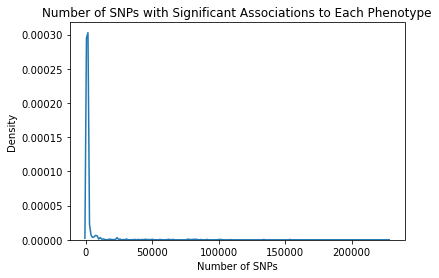

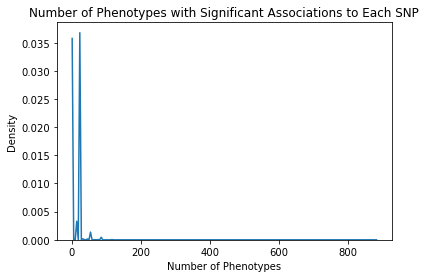

In [83]:
num_snp_per_phen = np.sum(sig_data_binary_array, axis=1)
fig = kde_wrapper(num_snp_per_phen)
plt.xlabel('Number of SNPs')
plt.title('Number of SNPs with Significant Associations to Each Phenotype')

num_phen_per_snp = np.sum(sig_data_binary_array, axis=0)
fig = kde_wrapper(num_phen_per_snp)
plt.xlabel('Number of Phenotypes')
plt.title('Number of Phenotypes with Significant Associations to Each SNP')

DescribeResult(nobs=3892, minmax=(0, 99), mean=55.78263103802672, variance=397.60835411415326, skewness=-0.178859123903127, kurtosis=0.9279745716416032)
ModeResult(mode=array([50]), count=array([2405]))
DescribeResult(nobs=2042472, minmax=(0, 99), mean=43.53809550387961, variance=697.0094859740672, skewness=0.14213059401455244, kurtosis=-0.8608179137407355)
ModeResult(mode=array([50]), count=array([606838]))


Text(0.5, 1.0, 'Number of SNPs in Each NMF Loading Component')

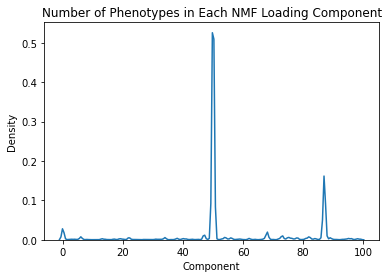

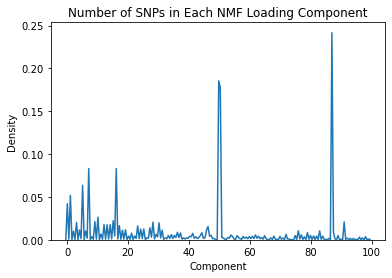

In [10]:
basis_top_comp = np.argmax(gwas_basis, axis=1)
mixture_top_comp = np.argmax(gwas_mixture, axis=0)

fig = kde_wrapper(basis_top_comp)
plt.xlabel('Component')
plt.title('Number of Phenotypes in Each NMF Loading Component')

fig = kde_wrapper(mixture_top_comp)
plt.xlabel('Component')
plt.title('Number of SNPs in Each NMF Loading Component')

In [129]:
np.where(basis_top_comp==10)[0]

array([2206])

In [14]:
sig_df_to_array[((sig_df_to_array['phen_ind']==2206))]

,,pvalue,pval_mlog,snp_ind,phen_ind
Reference SNP cluster ID,phenotype,,,,
10:104227791_GA_G,30140_irnt,3.868880e-08,7.412415,212,2206
10:104697128_CA_C,30140_irnt,1.216340e-08,7.914945,275,2206
10:104819507_TA_T,30140_irnt,1.285200e-08,7.891029,295,2206
10:104883968_AT_A,30140_irnt,5.796500e-09,8.236834,299,2206
10:104928771_TA_T,30140_irnt,9.380790e-09,8.027761,304,2206
...,...,...,...,...,...
rs999895,30140_irnt,2.198460e-08,7.657881,2042392,2206
rs9999025,30140_irnt,1.016090e-08,7.993068,2042397,2206
rs9999262,30140_irnt,2.429560e-49,48.614472,2042409,2206


In [11]:
sig_df_to_array[((sig_df_to_array['phen_ind']==2206) & (sig_df_to_array['snp_ind'].isin(np.where(mixture_top_comp==10)[0])))]

,,pvalue,pval_mlog,snp_ind,phen_ind
Reference SNP cluster ID,phenotype,,,,
10:28786671_GGGAAGGAAGGAA_G,30140_irnt,1.606530e-16,15.794111,1322,2206
10:28789967_CA_C,30140_irnt,1.213070e-12,11.916114,1323,2206
10:28792532_GTTT_G,30140_irnt,2.917410e-30,29.535003,1324,2206
10:28795697_TTG_T,30140_irnt,5.405610e-30,29.267155,1325,2206
10:28799520_CTT_C,30140_irnt,1.581540e-29,28.800920,1326,2206
...,...,...,...,...,...
rs9998340,30140_irnt,1.863880e-36,35.729582,2042338,2206
rs999895,30140_irnt,2.198460e-08,7.657881,2042392,2206
rs9999262,30140_irnt,2.429560e-49,48.614472,2042409,2206


In [12]:
np.where(mixture_top_comp==10)[0].shape

(25430,)

Text(0.5, 1.0, 'Comparing SNP and Phenotype Counts for Each Component')

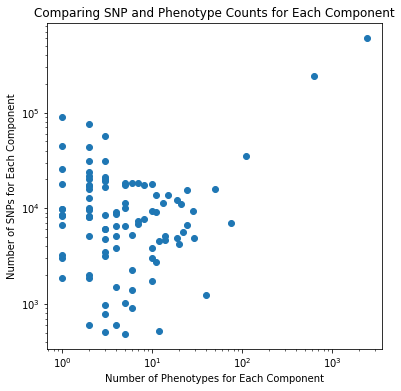

In [125]:
num_phen_each_comp = []
num_snps_each_comp = []
for i in range(100):
    num_phen_each_comp.append(len(np.where(basis_top_comp==i)[0]))
    num_snps_each_comp.append(len(np.where(mixture_top_comp==i)[0]))

fig = plt.figure(figsize=(6,6))
fig.patch.set_facecolor('white')

plt.scatter(num_phen_each_comp, num_snps_each_comp)

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Number of Phenotypes for Each Component')
plt.ylabel('Number of SNPs for Each Component')

plt.title('Comparing SNP and Phenotype Counts for Each Component')

In [113]:
p = np.array(sig_df[sig_df['phen_ind'].isin(np.where(np.sum(gwas_basis, axis=1)==0)[0])]['pvalue'])
# sig_df[sig_df['snp_ind'].isin(np.where(np.sum(gwas_mixture, axis=0)==0)[0])]

DescribeResult(nobs=414, minmax=(7.304527079535204, 11.77327639647506), mean=7.755957859169442, variance=0.20329001151801052, skewness=3.2719287157368626, kurtosis=18.866173162361928)
ModeResult(mode=array([7.4182585]), count=array([2]))


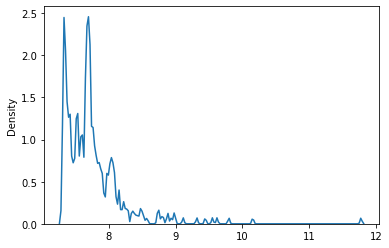

In [116]:
fig = kde_wrapper(-np.log10(p))

In [110]:
np.where(np.sum(gwas_mixture, axis=0)==0)[0].shape

(391,)

In [111]:
np.where(np.sum(gwas_basis, axis=1)==0)[0].shape

(110,)